# Assignment 2: Model Forensics

Read `Assignment_2_Model_Forensics.docx` for the full assignment. The questions below follow the same order and point breakdown. Complete the code marked TODO and write your explanations in the answer cells. Add cells when you need more space.

You may use AI to help write code. However, your explanations, interpretations, and answers to the questions must be your own work.

## Getting started

Unzip the full student package and keep the files together. If you're working in Jupyter or VS Code, open this notebook from the `Assignment_2_Student` folder.

If you're using Google Colab, open the notebook first, upload the full ZIP file, unzip it, and set your working directory to `Assignment_2_Student` before running the setup cells. The notebook needs the data, model files, and `forensics_tools.py`, so uploading the notebook alone won't work.

Use Python 3.11 or newer. `requirements.txt` lists the package versions used for this assignment. If you need to install them, uncomment and run the next cell, then restart the kernel.

The supplied models were saved with scikit-learn 1.8.0. If you can't load them, check that version first. `rebuild_models.py` can recreate them with the original training data and settings. Don't open it before recording your Part I model guesses, since it reveals the model types. Keep the settings unchanged for Parts II and III.

In [1]:
# Run once only if your notebook environment needs these dependencies:
%pip install -r requirements.txt

  Using cached numpy-2.3.5-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 17.1 MB/s  0:00:009.9 MB/s eta 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... error
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [12 lines of output]
      + meson setup /private/var/folders/tj/xmb08sjx3rjdxx14_k0r05mm0000gn/T/pip-install-zqp7v6bd/pandas_e8dd05d799a9489ba0f80c81e4939023 /private/var/folders/tj/xmb08sjx3rjdxx14_k0r05mm0000gn/T/pip-install-zqp7v6bd/pandas_e8dd05d799a9489ba0f80c81e4939023/.mesonpy-avq2cfr3/build -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --vsenv --native-file=/private/var/folders/tj/xmb08sjx3rjdxx14_k0r05mm0000gn/T/pip-install-zqp7v6bd/pandas_e8dd05d799a9489ba0f80c81e4939023/.mesonpy-avq2cfr3/bui

In [56]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error
import sklearn
from forensics_tools import (load_split, load_dictionary, load_model,
    refit_regression, positive_probability, predict_at_threshold,
    perturb_inputs, flip_rate)
ROOT = Path.cwd()
assert (ROOT / 'data').is_dir(), 'Open this notebook inside the unzipped student folder.'
print('scikit-learn:', sklearn.__version__)
print('Setup complete. IDs and target are excluded by load_split().')

scikit-learn: 1.9.0
Setup complete. IDs and target are excluded by load_split().


## A quick example with a decision tree

Here is the basic pattern you'll use to train a decision tree in Python. `fit()` learns the splits from the training data. `predict()` uses those splits to assign labels to new rows. Give the model the same feature columns, in the same order, when you train and predict.

`max_depth` limits the depth of the tree, and `min_samples_leaf` sets the minimum number of training rows allowed in a leaf. `random_state` helps you reproduce the same result.

Run the example below and look at the predictions and tree diagram. These are practice data, separate from the assignment. You'll train new trees in Parts IV and V. In Part III, the trees are already trained, so don't call `fit()` on them.

In [57]:
# A small demonstration: predicting whether a help request needs escalation.
demo_X = pd.DataFrame({
    'wait_minutes': [5, 12, 20, 30, 40, 55, 70, 90],
    'open_cases':   [2,  3,  8, 10, 30, 35, 55, 70]})
demo_y = np.array([0, 0, 0, 0, 1, 1, 1, 1])
demo_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=2, random_state=42)
demo_tree.fit(demo_X, demo_y)
new_requests = pd.DataFrame({'wait_minutes': [15, 80], 'open_cases': [5, 60]})
print('Predicted labels:', demo_tree.predict(new_requests))
print('Class ordering:', demo_tree.classes_)
print('Probabilities:', demo_tree.predict_proba(new_requests))
print('Depth:', demo_tree.get_depth(), 'Leaves:', demo_tree.get_n_leaves())

Predicted labels: [0 1]
Class ordering: [0 1]
Probabilities: [[1. 0.]
 [0. 1.]]
Depth: 1 Leaves: 2


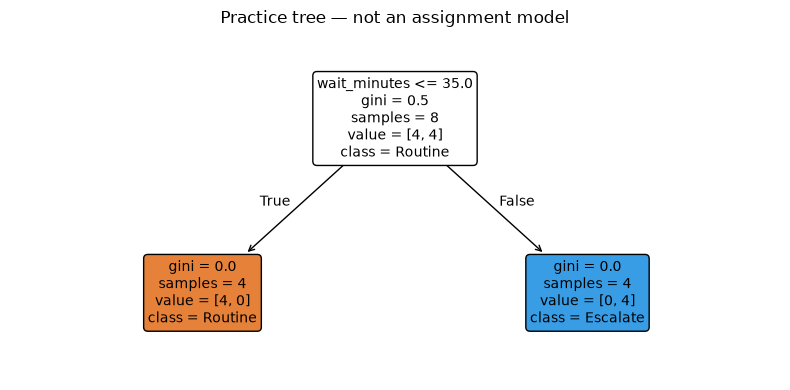

|--- wait_minutes <= 35.00
|   |--- class: 0
|--- wait_minutes >  35.00
|   |--- class: 1



In [58]:
# Visual and text representations of the learned rules.
plt.figure(figsize=(8, 4))
plot_tree(demo_tree, feature_names=list(demo_X.columns),
          class_names=['Routine', 'Escalate'], filled=True, rounded=True, fontsize=10)
plt.title('Practice tree — not an assignment model')
plt.tight_layout()
plt.show()
print(export_text(demo_tree, feature_names=list(demo_X.columns)))

### A few useful methods

- `predict_proba(X)` gives the probability for each class. Check `model.classes_` to see the column order.
- `get_depth()` and `get_n_leaves()` report the tree's depth and number of leaves.
- `apply(X)` gives the leaf ID for each row.
- `decision_path(X)` shows which nodes each row visits. Use `.toarray()` to view the result.
- `export_text()` prints the split rules; `plot_tree()` draws them.

For a split node, `tree.tree_.feature[node_id]` tells you which feature is used, and `tree.tree_.threshold[node_id]` gives the cutoff. A leaf has equal left and right child IDs, both −1. `tree.tree_.n_node_samples` gives the number of **training** rows at each node, even when you're making predictions on validation data.

If you pass `max_depth=3` to `plot_tree()`, the diagram only shows the upper levels. It doesn't change the fitted tree.

You can find more examples in the [DecisionTreeClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) and the [tree structure guide](https://scikit-learn.org/stable/auto_examples/tree/plot_unveil_tree_structure.html).

## Part I: The regularization mystery

**20 points**

These models predict monthly electricity usage in kWh. The features and outcomes are synthetic. Start with the exported coefficients and predictions; record your guesses before inspecting the model definitions or refitting code. The exported coefficients are for standardized features.

In [59]:
X1_train, y1_train, ids1_train = load_split('part1', 'train')
X1_val, y1_val, ids1_val = load_split('part1', 'validation')
coefficients = pd.read_csv(ROOT / 'data/part1/coefficients.csv')
predictions1 = {k: pd.read_csv(ROOT / f'data/part1/predictions_{k}_validation.csv')
                for k in ['A', 'B', 'C']}
print(coefficients.to_string(index=False))

            feature          A           B          C
         floor_area  45.044428  404.157144  98.670768
        survey_area  45.022259 -300.825585   0.000000
          occupants  51.974919   67.564758  62.908986
outside_temperature -40.355820  -51.397757 -46.982817
       building_age   3.149034    4.187326   0.000000
      meter_noise_1   1.875947    0.895275   0.000000
      meter_noise_2  -0.408892   -0.660260  -0.000000
      meter_noise_3   1.137067    1.051531   0.000000


### Question 1: Identify the models (5 points)

Which model is most likely ordinary linear regression, L1, and L2? Make a table for A, B, and C showing:

- The number of effectively zero coefficients, using an absolute tolerance of 0.000001.
- The sum of absolute coefficient values and the Euclidean length of the coefficient vector.
- Validation RMSE.

Leave the intercept out of the coefficient summaries. Use the table to explain your guesses, and mention any uncertainty. A coefficient pattern can suggest a model type without proving it.

In [60]:
# Part I, Question 1
# TODO: Calculate the coefficient summaries for A, B, and C.
# TODO: Join each prediction file to the validation labels using observation_id.
# TODO: Calculate RMSE and put the results in one table.
# Hint: np.sqrt(mean_squared_error(y_true, y_pred))
# TODO: Record your guesses before moving on.
TOL = 1e-6
coef = coefficients.set_index('feature')
truth = pd.Series(y1_val.values, index=ids1_val.values)
q1_table = pd.DataFrame({k: {
    'zero_count': (coef[k].abs() <= TOL).sum(),
    'sum_abs': coef[k].abs().sum(),
    'euclid_len': np.sqrt((coef[k] ** 2).sum()),
    'val_rmse_kWh': np.sqrt(mean_squared_error(truth[predictions1[k].observation_id], predictions1[k].prediction)),
} for k in 'ABC'}).T
print(q1_table.round(3))
model_identities = {'A': 'L2 (Ridge)', 'B': 'ordinary linear regression', 'C': 'L1 (Lasso)'}


   zero_count  sum_abs  euclid_len  val_rmse_kWh
A         0.0  188.968      91.656        34.188
B         0.0  830.740     510.946        24.472
C         5.0  208.563     126.099        25.852


**Your answer:**

Explain your model guesses using the numbers in your table. What remains uncertain?

*Write your answer here.*
1. A seems to be L2 Ridge Regression.
2. B seems to be Regular Linear Regression.
3. C L1 Lasso Regression.

### Question 2: Investigate redundant information (4 points)

Find at least one pair or group of correlated features using the training data. Report their correlations and compare their standardized coefficients in A, B, and C. Explain how the models share weight across these features and whether the correlations and coefficients tell the same story.

In [61]:
# Part I, Question 2
# TODO: Identify a correlated pair or group using X1_train.
# TODO: Report its training correlations and coefficients in A, B, and C.
# Hint: X1_train.corr()
c = X1_train.corr().abs().where(np.triu(np.ones((8, 8), bool), 1)).stack()
f1, f2 = c.idxmax()
print(f1, f2, X1_train[f1].corr(X1_train[f2]))
print(coef.loc[[f1, f2]].round(3))

floor_area survey_area 0.9999929258088903
                  A        B       C
feature                             
floor_area   45.044  404.157  98.671
survey_area  45.022 -300.826   0.000


**Your answer:**

Describe the overlap between the features and how each model handles it.

*Write your answer here.*
- floor_area and survey_area have a training correlation of 0.99999.
- B gives +404 and −301, which nearly cancel.
- Correlation says the two features are interchangeable. The coefficients disagree about how to use them, so the two don't tell the same story.


In [62]:
# Check correlations among training features
print(X1_train.corr().to_string())

                     floor_area  survey_area  occupants  outside_temperature  building_age  meter_noise_1  meter_noise_2  meter_noise_3
floor_area             1.000000     0.999993   0.012381            -0.062803     -0.015400       0.061256       0.001264       0.012028
survey_area            0.999993     1.000000   0.012299            -0.062738     -0.015348       0.061262       0.001303       0.012059
occupants              0.012381     0.012299   1.000000            -0.045353      0.006514       0.041956       0.021864       0.010874
outside_temperature   -0.062803    -0.062738  -0.045353             1.000000     -0.009171      -0.006057       0.015798      -0.007254
building_age          -0.015400    -0.015348   0.006514            -0.009171      1.000000       0.038781      -0.021472       0.024899
meter_noise_1          0.061256     0.061262   0.041956            -0.006057      0.038781       1.000000       0.024441      -0.016400
meter_noise_2          0.001264     0.001303   0

### Question 3: Run a controlled removal experiment (7 points)

Look for an informative feature that L1 set to zero and a correlated feature that L1 retained. Remove the **retained** feature, then refit all three models. Keep the original settings, rows, and split, and fit preprocessing on training data only. If you can't find that pair, use the strongest redundant pair and explain your choice.

Compare the group’s coefficients, validation RMSE, and number of selected features before and after removal. Use the same 0.000001 tolerance when counting selected features.

In [63]:
# Part I, Question 3
# TODO: Name the retained feature you chose to remove.
# TODO: Compare the original and refitted coefficients for your group.
# TODO: Report before/after validation RMSE and selected feature counts.
# Hint: refitted_models['A'][-1].coef_ gives its standardized coefficients.
feature_to_remove = 'floor_area'  # the correlated feature L1 retained
rows = []
for k in 'ABC':
    for fit, drop in [('before', None), ('after', feature_to_remove)]:
        m = refit_regression(k, X1_train, y1_train, drop)
        X = X1_val.drop(columns=drop) if drop else X1_val
        cf = pd.Series(m[-1].coef_, X.columns)
        rows.append({'model': k, 'fit': fit, **cf.reindex([f1, f2]).to_dict(),
                     'val_rmse_kWh': np.sqrt(mean_squared_error(y1_val, m.predict(X))),
                     'n_selected': (cf.abs() > TOL).sum()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

model    fit  floor_area  survey_area  val_rmse_kWh  n_selected
    A before      45.044       45.022        34.188           8
    A  after         NaN       79.290        40.175           7
    B before     404.157     -300.826        24.472           8
    B  after         NaN      103.327        24.382           7
    C before      98.671        0.000        25.852           3
    C  after         NaN       98.665        25.841           3


**Your answer:**

Explain why you removed this feature and what changed when you refitted the models.

*Write your answer here.*

- I removed floor_area because the correlation between survey_area and floor_area is really high, I am curious what would be the best.
- Removing floor_area leaves C's RMSE almost unchanged. survey_area jumps from 0 to 98.7 and takes over the role.
- B's RMSE is also nearly the same.
- A's RMSE rises from 34.2 to 40.2.
- A and B each lose one selected feature (8 to 7). C stays at 3.


### Question 4: Evaluate the conclusion (4 points)

Do you agree with this statement: “A coefficient of zero means this feature contains no useful information”? Use your removal experiment to support your answer. Distinguish the information a feature contains from its role in one fitted model. Also explain why a coefficient's size is not automatically a causal effect.

**Your answer:**

Use your results from Question 3 to explain what a zero coefficient does—and does not—tell you. Then address the causal-effect claim.

*Write your answer here.*
- Disagree with the statement. survey_area was zeroed, yet it carries the same information as floor_area after the refit. Also, inherently, zero means the model assigned the importance elsewhere elsewhere, not that the feature is uninformative, its just that there's a lack of information that points to other information.
- Coefficient size depends on scaling, correlated features and regularization, so it isn't a causal effect. For example, B's +404 and −301 are not real effects.


## Part II: Find the model breaking point

**20 points**

This fitted logistic regression model predicts default within the next 12 months. Label 1 means default; label 0 means no default. It's a fictional model for this exercise.

Use a threshold of 0.50: probabilities at or above 0.50 are class 1. Don't retrain the model or change the threshold.

In [64]:
X2_train, y2_train, ids2_train = load_split('part2', 'train')
X2_val, y2_val, ids2_val = load_split('part2', 'validation')
probe_model = load_model('logistic_probe')
dictionary2 = load_dictionary('part2')
p2 = positive_probability(probe_model, X2_val)
eligible_positions = np.flatnonzero((p2 >= 0.20) & (p2 <= 0.80))
print('Eligible validation observations:', len(eligible_positions))
print(dictionary2.to_string())

Eligible validation observations: 185
                                               description   unit   minimum    maximum     step
feature                                                                                        
annual_income                          Annual gross income    USD  20000.00  200000.00  100.000
credit_score                                  Credit score  score    450.00     850.00    1.000
debt_ratio                 Debt payments divided by income  ratio      0.02       0.85    0.001
account_years                   Years since account opened  years      0.10      30.00    0.100
credit_utilization  Used revolving credit divided by limit  ratio      0.01       0.99    0.001


/opt/homebrew/Cellar/jupyterlab/4.5.2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.8.0 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpick

### Question 1: Establish the baseline (3 points)

Choose one validation observation with predicted probability between 0.20 and 0.80. Report its ID, true label, original feature values, predicted probability, and predicted class. Choose at least four numerical features to investigate, and list their valid ranges and measurement precision from the feature dictionary. Explain why you chose this observation.

- Baseline observation part2_01432 has a true label of 0 and a predicted probability of 0.399 (classified as 0). It was chosen for sensitivity probing because it lies close enough to the 0.50 threshold that small, single-feature adjustments can easily flip the predicted class.

In [65]:
# Part II, Question 1
# TODO: Choose a position from eligible_positions.
# TODO: Choose at least four numerical features.
# TODO: Report the ID, true label, feature values, probability, and class.
# TODO: Report the ranges and precision for features_to_probe.
baseline_position = eligible_positions[np.argmin(np.abs(p2[eligible_positions] - 0.40))]
features_to_probe = list(X2_train.columns)
baseline2 = X2_val.iloc[[baseline_position]].copy()
orig_class = predict_at_threshold(probe_model, baseline2)[0]
print('ID:', ids2_val.iloc[baseline_position], '| true label:', y2_val.iloc[baseline_position])
print('probability:', round(p2[baseline_position], 4), '| class:', orig_class)
print(baseline2.T.rename(columns={baseline2.index[0]: 'value'}))
print(dictionary2.loc[features_to_probe, ['unit', 'minimum', 'maximum', 'step']])

ID: part2_01432 | true label: 0
probability: 0.3994 | class: 0
                        value
annual_income       180700.00
credit_score           628.00
debt_ratio               0.65
account_years           24.00
credit_utilization       0.54
                     unit   minimum    maximum     step
feature                                                
annual_income         USD  20000.00  200000.00  100.000
credit_score        score    450.00     850.00    1.000
debt_ratio          ratio      0.02       0.85    0.001
account_years       years      0.10      30.00    0.100
credit_utilization  ratio      0.01       0.99    0.001


**Your answer:**

Explain why this observation is useful for your experiment.

*Write your answer here.*

- Flips: debt_ratio up to 0.692, credit_utilization up to 0.619, credit_score down to 592, annual_income down to 158,500, account_years down to 19.1.
- The other five directions are infeasible. The endpoint evidence is in the table.

### Question 2: Locate one feature boundary at a time (8 points)

For each chosen feature, find the nearest allowed value that changes the predicted class. Search both directions while keeping every other feature fixed. Respect the feature's range and precision.

Show a value that flips the prediction and the adjacent value toward the original input that doesn't. You may search numerically or calculate the boundary from coefficients, but check the result with the prediction function. If no allowed value flips the class, show the endpoint results and report that the flip is not feasible.

In [66]:
# Part II, Question 2
# TODO: Search for a one-feature class flip for each feature you chose.
# TODO: Verify the nearest flip value and its adjacent no-flip value.
# TODO: For infeasible flips, report both range endpoints and their predictions.
# Hint: edited = baseline2.copy()
# Hint: edited.loc[edited.index[0], feature_name] = new_value
# Hint: positive_probability(probe_model, edited)[0]
# Hint: predict_at_threshold(probe_model, edited, 0.50)[0]
rows = []
for f in features_to_probe:
    d, v0 = dictionary2.loc[f], baseline2[f].iloc[0]
    k0, kmax = round((v0 - d.minimum) / d.step), round((d.maximum - d.minimum) / d.step)
    for direction, ks in [('up', np.arange(k0 + 1, kmax + 1)), ('down', np.arange(k0 - 1, -1, -1))]:
        vals = np.round(d.minimum + ks * d.step, 6)
        cand = pd.concat([baseline2] * len(vals), ignore_index=True)
        cand[f] = vals
        flips = np.flatnonzero(predict_at_threshold(probe_model, cand) != orig_class)
        if len(flips) == 0:  # no feasible flip: show the endpoint
            rows.append({'feature': f, 'direction': direction, 'flip_value': np.nan,
                         'endpoint': vals[-1], 'p_endpoint': positive_probability(probe_model, cand.iloc[[-1]])[0]})
            continue
        j = flips[0]
        adj = vals[j - 1] if j > 0 else v0  # adjacent value toward the original
        both = baseline2.copy().iloc[[0, 0]].reset_index(drop=True)
        both[f] = [vals[j], adj]
        p = positive_probability(probe_model, both); c = predict_at_threshold(probe_model, both)
        rows.append({'feature': f, 'direction': direction, 'original': v0, 'flip_value': vals[j],
                     'p_flip': p[0], 'class_flip': c[0], 'adjacent_value': adj, 'p_adjacent': p[1], 'class_adjacent': c[1]})
boundaries = pd.DataFrame(rows)
print(boundaries.round(4).to_string(index=False))

           feature direction  flip_value  endpoint  p_endpoint  original  p_flip  class_flip  adjacent_value  p_adjacent  class_adjacent
     annual_income        up         NaN 200000.00      0.3179       NaN     NaN         NaN             NaN         NaN             NaN
     annual_income      down  158500.000       NaN         NaN 180700.00  0.5001         1.0      158600.000      0.4997             0.0
      credit_score        up         NaN    850.00      0.0477       NaN     NaN         NaN             NaN         NaN             NaN
      credit_score      down     592.000       NaN         NaN    628.00  0.5028         1.0         593.000      0.4999             0.0
        debt_ratio        up       0.692       NaN         NaN      0.65  0.5009         1.0           0.691      0.4984             0.0
        debt_ratio      down         NaN      0.02      0.0014       NaN     NaN         NaN             NaN         NaN             NaN
     account_years        up         NaN 

**Your answer:**

Summarize your boundary checks, including the ranges and precision used in your search.

*Write your answer here.*

- Flips: debt_ratio up to 0.692, credit_utilization up to 0.619, credit_score down to 592, annual_income down to 158,500, account_years down to 19.1.
- The other five directions are infeasible. The endpoint evidence is in the table.

### Question 3: Compare sensitivity fairly (5 points)

Can you compare a change in dollars directly with a change in years or a ratio? For each successful flip, divide the absolute change by that feature's training standard deviation and rank the results. Report zero-variance features as undefined.

Compare your ranking with the absolute standardized logistic coefficients. Explain any differences due to valid ranges or measurement precision.

In [67]:
# Part II, Question 3
# TODO: Report raw changes and changes measured in training standard deviations.
# TODO: Rank the feasible flips and compare with absolute standardized coefficients.
# Hint: probe_model[-1].coef_[0] follows the feature order in X2_train.
training_sd2 = X2_train.std(ddof=0)
ok = boundaries.dropna(subset=['flip_value']).copy()
ok['raw_change'] = (ok.flip_value - ok.original).abs()
ok['sd_change'] = ok.raw_change / ok.feature.map(training_sd2)
best = ok.loc[ok.groupby('feature').sd_change.idxmin()].sort_values('sd_change')
best['sd_rank'] = range(1, len(best) + 1)
best['abs_coef'] = best.feature.map(pd.Series(np.abs(probe_model[-1].coef_[0]), X2_train.columns))
best['coef_rank'] = best.abs_coef.rank(ascending=False).astype(int)
print(best[['feature', 'direction', 'raw_change', 'sd_change', 'sd_rank', 'abs_coef', 'coef_rank']].round(4).to_string(index=False))

           feature direction  raw_change  sd_change  sd_rank  abs_coef  coef_rank
        debt_ratio        up       0.042     0.1752        1    2.3487          1
credit_utilization        up       0.079     0.2801        2    1.4660          2
      credit_score      down      36.000     0.3134        3    1.3376          3
     annual_income      down   22200.000     0.4240        4    0.9637          4
     account_years      down       4.900     0.5654        5    0.7334          5


**Your answer:**

Explain why the raw changes are not directly comparable and what your standardized comparison shows.

*Write your answer here.*
- Raw dollars, years and ratios have different units, so they can't be ranked directly.
- In SDs the order is debt_ratio (0.175), credit_utilization (0.280), credit_score (0.313), annual_income (0.424), account_years (0.565), which matches the absolute coefficient ranking exactly, so there are no differences to explain (same unis).

### Question 4: Interpret the result and its limits (4 points)

Explain what happens to the probability as an input crosses the class boundary. Does a class flip necessarily mean a large probability change?

Check whether your edited observations make sense together: individual values can be in range while the combination is implausible. Explain why this one observation doesn't establish global sensitivity or a causal effect.

**Your answer:**

Discuss probability changes, plausible feature combinations, and what you can conclude from this single observation.

*Write your answer here.*

- Probability moves smoothly across the boundary, since the flips goes from 0.5001 to 0.5028. Adjacent values at 0.4984 to 0.4999. A class flip is not a large probability change.
- Plausibility - credit_score falling from 628 to 592 while income stays at $180k is likely unrealistic.
- One observation cant determine causality.

## Part III: Same accuracy different behavior

**20 points**

The target is service escalation: 1 means escalation, 0 means routine handling. Both trees are already fitted. Use validation data for your investigation and don't call `fit()` on either tree.

In [68]:
X3_train, y3_train, ids3_train = load_split('part3', 'train')
X3_val, y3_val, ids3_val = load_split('part3', 'validation')
tree_A, tree_B = load_model('tree_A'), load_model('tree_B')
dictionary3 = load_dictionary('part3')

/opt/homebrew/Cellar/jupyterlab/4.5.2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.8.0 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


### Question 1: Audit tree structure (4 points)

For each tree, report training and validation accuracy, maximum depth, number of leaves, and the minimum and median number of training rows per leaf. Explain what these results suggest about complexity and possible overfitting. They are evidence, not guarantees.

In [69]:
# Part III, Question 1
# TODO: Build a structure table for tree_A and tree_B.
# Hint: tree_A.get_depth() and tree_A.get_n_leaves()
# Hint: leaf_mask = tree_A.tree_.children_left == tree_A.tree_.children_right
# Hint: counts = tree_A.tree_.n_node_samples[leaf_mask]
# Use training leaf counts, not validation counts.
def structure(t):
    leaf = t.tree_.children_left == t.tree_.children_right
    n = t.tree_.n_node_samples[leaf]
    return {'train_acc': t.score(X3_train, y3_train), 'val_acc': t.score(X3_val, y3_val),
            'depth': t.get_depth(), 'leaves': t.get_n_leaves(),
            'min_leaf_n': n.min(), 'median_leaf_n': np.median(n)}
structure_table = pd.DataFrame({'A': structure(tree_A), 'B': structure(tree_B)}).T
print(structure_table.round(3))

   train_acc  val_acc  depth  leaves  min_leaf_n  median_leaf_n
A      0.875    0.858    4.0    15.0        35.0           70.0
B      0.889    0.844    8.0    76.0         8.0           14.0


**Your answer:**

Compare the trees’ complexity and what the training/validation results suggest.

*Write your answer here.*

1. Tree A: Depth 4, 15 leaves, min leaf 35, median 70 (Train: 0.875, Val: 0.858, Gap: 0.017).
2. Tree B: Depth 8, 76 leaves, min leaf 8, median 14 (Train: 0.889, Val: 0.844, Gap: 0.045).
3. Conclusion: B's higher complexity and larger train-val gap suggest overfitting, though not proof.

### Question 2: Investigate disagreements (6 points)

Calculate the disagreement rate over all validation rows. Report at least 10 disagreement cases with IDs, true labels, both predictions, and relevant features. If there are fewer than 10, use all of them.

Find a feature range or combination where disagreements seem concentrated, and compare its disagreement rate with the overall rate. Trace at least two cases through both trees using the actual split thresholds.

In [70]:
# Part III, Question 2
# TODO: Calculate the overall disagreement rate and report disagreement cases.
# TODO: Compare one feature range or combination with the overall rate.
# TODO: Trace two observations through both trees.
# Hint: np.flatnonzero(tree_A.predict(X3_val) != tree_B.predict(X3_val))
# Hint: tree_A.decision_path(X3_val.iloc[[position]]).toarray()
# Hint: tree_A.apply(X3_val.iloc[[position]])
# Optional: show the upper levels to help you inspect the rules.
# plt.figure(figsize=(16, 7))
# plot_tree(tree_A, feature_names=list(X3_train.columns),
#           class_names=['Routine', 'Escalate'], max_depth=3,
#           filled=True, rounded=True, fontsize=8)
# plt.show()
pred_A, pred_B = tree_A.predict(X3_val), tree_B.predict(X3_val)
dis = pred_A != pred_B
print('Disagreement rate:', dis.mean().round(4), f'({dis.sum()} of {len(dis)})')
cases = X3_val[dis].assign(observation_id=ids3_val[dis], true=y3_val[dis], pred_A=pred_A[dis], pred_B=pred_B[dis])
print(cases.head(10).round(3).to_string(index=False))

# concentration: disagreement rate by feature quantile bin
for f in X3_val.columns:
    rate = pd.Series(dis).groupby(pd.qcut(X3_val[f].values, 4, duplicates='drop'), observed=True).mean()
    print(f, rate.round(3).to_dict())
hi = X3_val.service_complexity > 0.75
print('service_complexity > 0.75:', hi.sum(), 'rows, disagreement rate', dis[hi].mean().round(4), 'vs overall', dis.mean().round(4))

def trace(tree, row):
    t = tree.tree_
    for node in tree.decision_path(row).indices:
        if t.children_left[node] == t.children_right[node]:
            print(f'  leaf {node}: class {tree.classes_[t.value[node].argmax()]}, n={t.n_node_samples[node]}')
        else:
            f, thr = row.columns[t.feature[node]], t.threshold[node]
            print(f'  {f} = {row[f].iloc[0]} {"<=" if row[f].iloc[0] <= thr else ">"} {thr:.3f}')
for pos in np.flatnonzero(dis)[:2]:
    row = X3_val.iloc[[pos]]
    print('\n', ids3_val.iloc[pos], 'true', y3_val.iloc[pos])
    for name, tr in [('Tree A', tree_A), ('Tree B', tree_B)]:
        print(name); trace(tr, row)

Disagreement rate: 0.0438 (35 of 800)
 wait_minutes  backlog_cases  dissatisfaction  agent_experience  service_complexity observation_id  true  pred_A  pred_B
         83.3             93            0.143              11.0               0.969    part3_00978     1       1       0
         52.1            176            0.798               8.2               0.855    part3_01608     1       0       1
        103.4              9            0.871              10.1               0.259    part3_00318     0       1       0
         90.4            192            0.261              13.4               0.507    part3_01913     1       1       0
         45.5            143            0.819               9.1               0.933    part3_01719     1       0       1
         55.6             39            0.126               3.4               0.107    part3_01857     0       0       1
         83.1            195            0.161              10.8               0.984    part3_01526     1       1   

**Your answer:**

Describe the disagreement pattern and explain the two paths you traced. Include actual feature values and split cutoffs.

*Write your answer here.*

- The disagreement rate is 35 of 800.
- It is concentrated where service_complexity > 0.75: 9.4% there.
- In part3_00978, both trees reach service_complexity = 0.969 > 0.944. B then splits on dissatisfaction = 0.143 <= 0.244 into a leaf of 13 rows and predicts 0, while A predicts 1 and the true label is 1.
- In part3_01608, A splits service_complexity at 0.813 and B at 0.839, and B goes deeper into a leaf of 8 rows.

### Question 3: Design a fair perturbation experiment (6 points)

Use `perturb_inputs()` to select 50 validation rows and create 20 perturbed versions of each, with seed 42. The helper adds uniform changes within 0.05 training standard deviations, rounds to measurement precision, and clips to valid ranges. Rounding may add half a measurement step to the final change. Categorical features stay unchanged.

Use the same perturbed rows for both trees. Report each tree's prediction flip rate, give one actual example, and discuss whether the edited feature combinations are plausible.

In [71]:
# Part III, Question 3
# TODO: Report flip_rate(tree_A, original3, perturbed3) and the result for B.
# TODO: Find and report one actual perturbation example.
# If one tree has no flips in this sample, report that rather than inventing an example.
original3, perturbed3, source_positions3 = perturb_inputs(
    X3_val, X3_train, dictionary3, seed=42)
print('Flip rate A:', flip_rate(tree_A, original3, perturbed3))
print('Flip rate B:', flip_rate(tree_B, original3, perturbed3))

# one actual example: a perturbed row whose Tree B prediction differs from its original
before_B = np.repeat(tree_B.predict(original3), 20)
j = np.flatnonzero(tree_B.predict(perturbed3) != before_B)[0]
print(pd.DataFrame({'original': original3.iloc[j // 20], 'perturbed': perturbed3.iloc[j]}))
print('Tree B:', before_B[j], '->', tree_B.predict(perturbed3.iloc[[j]])[0],
      '| Tree A:', tree_A.predict(original3.iloc[[j // 20]])[0], '->', tree_A.predict(perturbed3.iloc[[j]])[0])

Flip rate A: 0.0
Flip rate B: 0.008
                    original  perturbed
wait_minutes          57.000     55.800
backlog_cases         19.000     17.000
dissatisfaction        0.121      0.116
agent_experience      14.500     14.500
service_complexity     0.782      0.796
Tree B: 0 -> 1 | Tree A: 0 -> 0


**Your answer:**

Compare the flip rates and discuss your example. Is the edited observation plausible?

*Write your answer here.*
- Tree A has a flip rate of 0.0 and Tree B has 0.008. Discuss the example the cell printed and whether the perturbed combination is plausible.

### Question 4: Make a deployment recommendation (4 points)

Recommend Tree A, Tree B, or revision of both. Support your choice with leaf sizes, traced paths, and perturbation results; don't base it on the small accuracy difference alone. Explain why stable predictions are not enough to establish that a model is correct or suitable.

Once you've made your choice, check its test accuracy once. Don't change the tree settings after this check.

In [72]:
# Part III, Question 4
chosen_tree = None  # TODO: Select tree_A or tree_B for the final check.
# If you recommend revising both, choose one as the current baseline and explain why.
if chosen_tree is not None:
    X3_test, y3_test, ids3_test = load_split('part3', 'test')
    print('Final test accuracy:', chosen_tree.score(X3_test, y3_test))

**Your answer:**

State your recommendation and explain the evidence behind it. Report the final test check and one limitation.

*Write your answer here.*

- larger leaves (minimum 35 against 8)
- zero flips against 0.008
- traced paths where B relies on small leaves


## Part IV: Construct data that defeats a model

**20 points**

You'll create the data for this part. Keep the model settings below fixed; your job is to design the dataset, not tune the models.

The target is logistic regression holdout accuracy below 70% and decision tree holdout accuracy above 90%. There are 10 holdout rows, so this means at most 6 correct predictions for logistic regression and all 10 correct for the tree. You may revise your data, but keep a short record of your attempts.

### Question 1: Design and explain the dataset (5 points)

Create exactly 40 distinct feature pairs with two numerical features, `x1` and `x2`, both between −5 and 5. Include 20 observations of each class in `y`. Use one coherent rule based on the two features to assign labels.

Don't use an automatic dataset generator, copy an existing dataset, assign labels by row number or split membership, or put the target directly into a feature. Save your CSV and explain why your design should favor one model.

In [73]:
# Part IV, Question 1
# TODO: Create a DataFrame with columns ['x1', 'x2', 'y'].
# TODO: Keep a brief construction log as you try different designs.
# Rule: y = 1 if max(|x1|, |x2|) < 2.5 (inside a central square), else 0. Points were typed by hand.
pts = [(-1.8, 1.5), (-0.6, 0.9), (0.7, 1.9), (1.9, 1.2), (1.4, -0.5), (0.3, -1.6), (-1.2, -1.1), (-2.0, -0.3), (-0.4, -0.2), (1.1, 0.4),
       (-1.5, 2.0), (0.9, -2.0), (2.1, -1.5), (-0.2, 1.8), (1.6, 2.1), (-2.1, -1.9), (0.1, 0.6), (-0.9, -1.9), (1.8, -0.1), (-1.1, 0.3),
       (-3.4, 1.0), (-4.1, -2.2), (-3.8, 3.5), (-4.6, 0.2), (-3.2, -3.9), (3.5, -1.2), (4.2, 2.0), (3.9, -3.6), (4.7, -0.4), (3.3, 3.8),
       (1.3, 3.6), (-1.4, 4.2), (0.5, 4.8), (-0.3, 3.3), (2.0, 4.4), (-1.7, -3.5), (1.2, -4.3), (0.2, -4.8), (-0.8, -3.2), (2.2, -3.9)]
my_data = pd.DataFrame(pts, columns=['x1', 'x2'])
my_data['y'] = (np.maximum(my_data.x1.abs(), my_data.x2.abs()) < 2.5).astype(int)
assert list(my_data.columns) == ['x1', 'x2', 'y']
assert len(my_data) == 40 and not my_data[['x1', 'x2']].duplicated().any()
assert my_data.y.value_counts().to_dict() == {0: 20, 1: 20}
assert my_data[['x1', 'x2']].ge(-5).all().all()
assert my_data[['x1', 'x2']].le(5).all().all()
my_data.to_csv('my_part4_data.csv', index=False)

construction_log = pd.DataFrame([
    ('1', 'XOR: y=1 if x1*x2>0, 10 points per quadrant', 'logistic 0.3, tree 0.9 (missed target)'),
    ('2', 'Center square: y=1 if max(|x1|,|x2|)<2.5, 20 inside / 20 outside', 'logistic 0.2, tree 1.0 (both met)')],
    columns=['attempt', 'design', 'seed-42 holdout result'])
print(construction_log.to_string(index=False))

attempt                                                           design                 seed-42 holdout result
      1                      XOR: y=1 if x1*x2>0, 10 points per quadrant logistic 0.3, tree 0.9 (missed target)
      2 Center square: y=1 if max(|x1|,|x2|)<2.5, 20 inside / 20 outside      logistic 0.2, tree 1.0 (both met)


**Your answer:**

Explain your label rule, why you chose this structure, and what you changed between attempts.

*Write your answer here.*
- The rule is y = 1 if max(x1 y x2) < 2.5. The first attempt was XOR (logistic 0.3, tree 0.9, missed the target), so I switched to the center square

### Question 2: Execute the fixed comparison (6 points)

Run the comparison below without changing the split or model settings. Don't add polynomial or interaction features. Report training and holdout accuracies, confusion matrices, and the settings. Check whether your design meets both targets. If it doesn't, report the result and explain it; partial credit is available for a valid, well-explained attempt.

In [74]:
# Part IV, Question 2 — keep these settings fixed.
    # TODO: Report training accuracies, confusion matrices, and settings for both models.
if my_data is not None:
    X4 = my_data[['x1', 'x2']]; y4 = my_data.y
    X4_train, X4_holdout, y4_train, y4_holdout = train_test_split(
        X4, y4, test_size=0.25, stratify=y4, random_state=42)
    logistic4 = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=10000))
    logistic4.fit(X4_train, y4_train)
    tree4 = DecisionTreeClassifier(max_depth=4, min_samples_leaf=2, random_state=42)
    tree4.fit(X4_train, y4_train)
    print('Logistic holdout accuracy:', logistic4.score(X4_holdout, y4_holdout))
    print('Tree holdout accuracy:', tree4.score(X4_holdout, y4_holdout))
    for name, m in [('Logistic (StandardScaler, C=1.0, max_iter=10000, threshold 0.50)', logistic4),
                    ('Tree (max_depth=4, min_samples_leaf=2, random_state=42)', tree4)]:
        print(f'\n{name}\n  train acc {m.score(X4_train, y4_train):.3f} | holdout acc {m.score(X4_holdout, y4_holdout):.3f}')
        print('  holdout confusion [[TN, FP], [FN, TP]]:', confusion_matrix(y4_holdout, m.predict(X4_holdout), labels=[0, 1]).tolist())

Logistic holdout accuracy: 0.2
Tree holdout accuracy: 1.0

Logistic (StandardScaler, C=1.0, max_iter=10000, threshold 0.50)
  train acc 0.633 | holdout acc 0.200
  holdout confusion [[TN, FP], [FN, TP]]: [[0, 5], [3, 2]]

Tree (max_depth=4, min_samples_leaf=2, random_state=42)
  train acc 1.000 | holdout acc 1.000
  holdout confusion [[TN, FP], [FN, TP]]: [[5, 0], [0, 5]]


**Your answer:**

State whether each target was met and explain the observed difference between the models.

*Write your answer here.*
- At seed 42, logistic scored 0.2 and the tree 1.0, so both targets were met. The tree trained to 1.000.
- Both targets were met: logistic holdout accuracy was 0.20 (needed 0.60 or less) and the tree's was 1.00 (needed 10 of 10). Logistic confusion matrix [[0, 5], [3, 2]]; tree confusion matrix [[5, 0], [0, 5]].


### Question 3: Visualize model behavior (5 points)

Plot all 40 points in two dimensions, with classes and training/holdout membership clearly marked. Show both fitted decision regions using the same feature limits. Explain which regions the logistic boundary cannot represent and how the tree divides the space. Report the tree's depth and number of leaves.

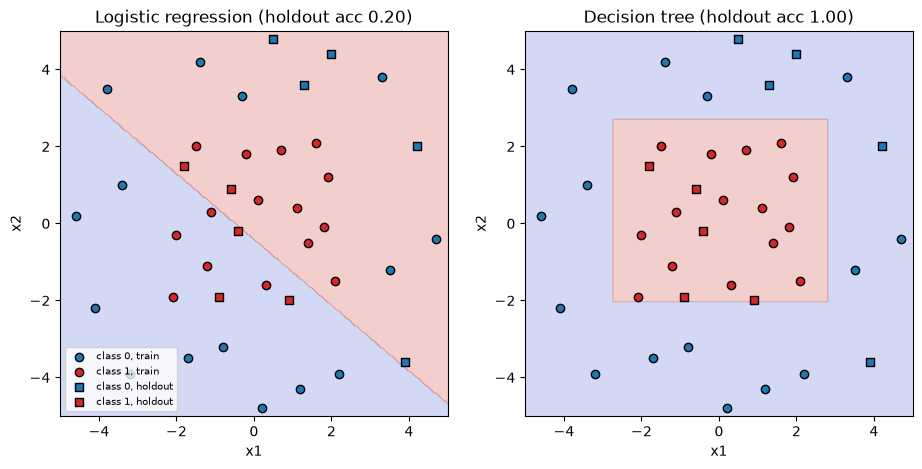

Tree depth: 4 | leaves: 5


In [75]:
# Part IV, Question 3
# TODO: Plot the two decision regions and overlay your 40 observations.
# TODO: Report tree4.get_depth() and tree4.get_n_leaves().
# Hint: Create a grid with np.meshgrid, then a DataFrame with ['x1', 'x2'].
# Call model.predict(grid), reshape the predictions, and use plt.contourf.
# Overlay observations with plt.scatter: color for class, marker for train/holdout.
xx, yy = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-5, 5, 300))
grid = pd.DataFrame({'x1': xx.ravel(), 'x2': yy.ravel()})
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, m) in zip(axes, [('Logistic regression', logistic4), ('Decision tree', tree4)]):
    ax.contourf(xx, yy, m.predict(grid).reshape(xx.shape), alpha=0.25, cmap='coolwarm')
    for idx, marker, label in [(X4_train.index, 'o', 'train'), (X4_holdout.index, 's', 'holdout')]:
        for cls, col in [(0, 'tab:blue'), (1, 'tab:red')]:
            s = my_data.loc[idx][my_data.loc[idx].y == cls]
            ax.scatter(s.x1, s.x2, c=col, marker=marker, edgecolor='k', label=f'class {cls}, {label}')
    ax.set(title=f'{name} (holdout acc {m.score(X4_holdout, y4_holdout):.2f})', xlabel='x1', ylabel='x2', xlim=(-5, 5), ylim=(-5, 5))
axes[0].legend(fontsize=7, loc='lower left')
plt.show()
print('Tree depth:', tree4.get_depth(), '| leaves:', tree4.get_n_leaves())

**Your answer:**

Use your plots to explain how the two models handle your data structure.

*Write your answer here.*

- The tree has depth 4 and 5 leaves. The logistic boundary is one line and can't represent a region surrounded on all sides.
- The logistic boundary is one straight line, so it can't separate the class 1 square in the middle from the class 0 points all around it. The tree uses straight cuts along x1 and x2 to box in the middle.


### Question 4: Assess the evidence (4 points)

Repeat the comparison with split seeds 0, 1, 2, 3, and 4. Keep your dataset and model settings unchanged. Report both holdout accuracies for every seed and explain why the results change.

What does the experiment show about your designed data structure? Why doesn't it establish that trees are generally better? Also explain why repeatedly inspecting the design holdout makes it unsuitable as an unbiased estimate of future performance.

In [76]:
# Part IV, Question 4
# TODO: Repeat the fixed comparison for split seeds [0, 1, 2, 3, 4].
# Keep the tree's random_state=42; change only the train/test split seed.
# TODO: Report both holdout accuracies for every seed, including unsuccessful results.
rows = []
for seed in [0, 1, 2, 3, 4]:
    Xt, Xh, yt, yh = train_test_split(X4, y4, test_size=0.25, stratify=y4, random_state=seed)
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=10000)).fit(Xt, yt)
    dt = DecisionTreeClassifier(max_depth=4, min_samples_leaf=2, random_state=42).fit(Xt, yt)
    rows.append({'split_seed': seed, 'logistic_holdout': lr.score(Xh, yh), 'tree_holdout': dt.score(Xh, yh)})
seed_results = pd.DataFrame(rows)
print(seed_results.to_string(index=False))
print(seed_results[['logistic_holdout', 'tree_holdout']].agg(['mean', 'min', 'max']).round(3))

 split_seed  logistic_holdout  tree_holdout
          0               0.3           0.8
          1               0.6           0.6
          2               0.4           1.0
          3               0.5           0.5
          4               0.3           1.0
      logistic_holdout  tree_holdout
mean              0.42          0.78
min               0.30          0.50
max               0.60          1.00


**Your answer:**

Discuss the split-to-split variation and the limits of your conclusion.

*Write your answer here.*

- Across seeds 0–4 logistic scores 0.3, 0.6, 0.4, 0.5, 0.3 (mean 0.42) and the tree 0.8, 0.6, 1.0, 0.5, 1.0 (mean 0.78).
- The tree's advantage is real but varies with the split.
- It shows a designed structural advantage on this dataset, not general superiority of trees.
- The holdout is used repeatedly, so it isn't an unbiased estimate of future performance.


## Part V: Evaluate conflicting deployment requirements

**20 points**

Here, label 1 means an equipment failure event and label 0 means no event. The features are normalized synthetic measurements. You'll fit your own models.

Management wants accuracy of at least 90%, no more than 5 original features, a false negative rate below 10%, an explainable model, and a prediction flip rate of at most 5% under the supplied perturbation protocol. For this exercise, “explainable” means a logistic model with at most 5 nonzero feature coefficients, or a tree of depth at most 3.

Use training data to fit models and validation data to choose settings, subsets, and thresholds. Leave the test set until you've chosen your final model.

In [77]:
X5_train, y5_train, ids5_train = load_split('part5', 'train')
X5_val, y5_val, ids5_val = load_split('part5', 'validation')
dictionary5 = load_dictionary('part5')
original5, perturbed5, _ = perturb_inputs(
    X5_val, X5_train, dictionary5, seed=42)

### Question 1: Run a documented candidate search (7 points)

Test ordinary or effectively unregularized logistic regression, L1 logistic regression, L2 logistic regression, and a decision tree. Try at least three regularization strengths for each regularized model and at least three tree depths, including one above 3. Compare thresholds 0.30, 0.50, and 0.70.

Keep a record of every setting you try. You may test additional candidates or feature subsets chosen from training data, but use validation data to select the final candidate.

**Python help:** In scikit-learn 1.8.0, use `solver='liblinear', l1_ratio=1` for L1 and `solver='lbfgs', l1_ratio=0` for L2. Smaller `C` means stronger regularization. For effectively unregularized logistic regression, you can use `C=1000000, l1_ratio=0, solver='lbfgs'`. Use a scaling pipeline for logistic models.

For a new tree, use the same `DecisionTreeClassifier(...)`, `fit()`, and `predict()` pattern as in the practice example.

In [78]:
# Part V, Question 1
# TODO: Fit the candidate models and keep a log of all settings and thresholds.
# Example of fitting a new tree:
# candidate_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42)
# candidate_tree.fit(X5_train, y5_train)
# candidate_pred = predict_at_threshold(candidate_tree, X5_val, threshold=0.50)
# TODO: Choose and justify your own candidate search.
TOL = 1e-6
base = make_pipeline(StandardScaler(), LogisticRegression(C=1e6, solver='lbfgs', l1_ratio=0, max_iter=10000)).fit(X5_train, y5_train)
top5 = list(X5_train.columns[np.argsort(-np.abs(base[-1].coef_[0]))[:5]])  # training-only subset
subsets = {'all8': list(X5_train.columns), 'top5': top5}

def lr(solver, C, l1_ratio):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, solver=solver, l1_ratio=l1_ratio, max_iter=10000))
grid = [('logistic_none', 'C=1e6', lambda: lr('lbfgs', 1e6, 0))]
grid += [('logistic_L1', f'C={C}', lambda C=C: lr('liblinear', C, 1)) for C in [0.01, 0.03, 0.1, 0.3, 1]]
grid += [('logistic_L2', f'C={C}', lambda C=C: lr('lbfgs', C, 0)) for C in [0.01, 0.1, 1]]
grid += [('tree', f'depth={d}', lambda d=d: DecisionTreeClassifier(max_depth=d, min_samples_leaf=10, random_state=42)) for d in [2, 3, 4, 6]]

def n_features(m):
    if hasattr(m, 'tree_'):
        f = m.tree_.feature; return len(set(f[f >= 0]))
    return int((np.abs(m[-1].coef_[0]) > TOL).sum())
def explainable(m):
    return m.get_depth() <= 3 if hasattr(m, 'tree_') else n_features(m) <= 5

models, rows = {}, []
for family, setting, make in grid:
    for sub, feats in subsets.items():
        m = make().fit(X5_train[feats], y5_train)
        models[(family, setting, sub)] = m
        for t in [0.30, 0.50, 0.70]:
            tn, fp, fn, tp = confusion_matrix(y5_val, predict_at_threshold(m, X5_val[feats], t), labels=[0, 1]).ravel()
            rows.append({'family': family, 'setting': setting, 'subset': sub, 'threshold': t,
                         'val_acc': (tn + tp) / len(y5_val), 'n_features': n_features(m),
                         'fnr': fn / (tp + fn) if tp + fn else np.nan, 'explainable': explainable(m),
                         'flip_rate': flip_rate(m, original5[feats], perturbed5[feats], threshold=t)})
log = pd.DataFrame(rows)
log['n_met'] = ((log.val_acc >= 0.90).astype(int) + (log.n_features <= 5) + (log.fnr < 0.10)
                + log.explainable + (log.flip_rate <= 0.05))
log['all_met'] = log.n_met == 5
print(len(log), 'configurations evaluated; subset top5 =', top5)
print(log.round(3).to_string(index=False))

78 configurations evaluated; subset top5 = ['load_index', 'warning_index', 'maintenance_gap', 'age_index', 'pressure_index']
       family setting subset  threshold  val_acc  n_features   fnr  explainable  flip_rate  n_met  all_met
logistic_none   C=1e6   all8        0.3    0.740           8 0.079        False      0.004      2    False
logistic_none   C=1e6   all8        0.5    0.849           8 0.159        False      0.014      1    False
logistic_none   C=1e6   all8        0.7    0.733           8 0.438        False      0.014      1    False
logistic_none   C=1e6   top5        0.3    0.729           5 0.085         True      0.007      4    False
logistic_none   C=1e6   top5        0.5    0.816           5 0.177         True      0.000      3    False
logistic_none   C=1e6   top5        0.7    0.733           5 0.446         True      0.011      3    False
  logistic_L1  C=0.01   all8        0.3    0.657           6 0.062        False      0.011      2    False
  logistic_L1  C=0.

**Your answer:**

Describe the settings and any training-only feature subsets you tested. Explain how you selected candidates.

*Write your answer here.*
- 78 configurations covering unregularized, L1 (5 strengths), L2 (3 strengths) and trees (depths 2, 3, 4, 6), with all 8 features or a training-only top-5 subset, at 3 thresholds.

### Question 2: Build the evidence table (5 points)

Choose your best candidate from each model family and say how you defined “best.” Report validation accuracy, feature count, FNR, explainability compliance, flip rate, threshold, and whether all five requirements are met.

Then lock one final candidate and threshold. Evaluate it once on test data and report the test results separately. Use perturbation seed 43 for this final check, and don't retune afterward.

**Metric hints:** `confusion_matrix(y, pred, labels=[0, 1]).ravel()` returns TN, FP, FN, TP. FNR is FN divided by TP + FN; report it as undefined if there are no positive cases.

Count logistic coefficients whose absolute value exceeds 0.000001. For a tree, count the unique feature indices used in splits, ignoring negative leaf entries. In Part V, apply the chosen threshold to both the original and perturbed rows when calculating flip rate.

In [79]:
# Part V, Question 2
# TODO: Build the validation evidence table with every required metric.
# Hint: flip_rate(candidate_model, original5, perturbed5, threshold=chosen_threshold)
# If a model uses a feature subset, pass that same subset to all prediction calls.
# TODO: Lock your model before loading test data.
# TODO: Lock its threshold too.
# TODO: List the input features, in training order.
    # TODO: Report final test accuracy, FNR, feature count, explainability, and flip rate.
    # Use final_features and final_threshold consistently. Do not tune after this check.
# "Best" = most requirements met on validation, ties broken by validation accuracy.
best = log.sort_values(['n_met', 'val_acc'], ascending=False).groupby('family').head(1)
print(best.sort_values('n_met', ascending=False).round(3).to_string(index=False))

top = best.sort_values(['n_met', 'val_acc'], ascending=False).iloc[0]
final_model = models[(top.family, top.setting, top.subset)]   # locked from validation results only
final_threshold = top.threshold
final_features = subsets[top.subset]
print('Locked:', top.family, top.setting, top.subset, 'threshold', final_threshold)
if final_model is not None and final_threshold is not None and final_features is not None:
    X5_test, y5_test, ids5_test = load_split('part5', 'test')
    final_pred = predict_at_threshold(
        final_model, X5_test[final_features], final_threshold)
    original_test, perturbed_test, _ = perturb_inputs(
        X5_test, X5_train, dictionary5, seed=43)
    tn, fp, fn, tp = confusion_matrix(y5_test, final_pred, labels=[0, 1]).ravel()
    test_result = {'test_acc': (tn + tp) / len(y5_test), 'fnr': fn / (tp + fn) if tp + fn else np.nan,
                   'n_features': n_features(final_model), 'explainable': explainable(final_model),
                   'flip_rate': flip_rate(final_model, original_test[final_features],
                                          perturbed_test[final_features], threshold=final_threshold)}
    print('FINAL TEST CHECK (run once):', {k: round(v, 3) if isinstance(v, float) else v for k, v in test_result.items()})

       family setting subset  threshold  val_acc  n_features   fnr  explainable  flip_rate  n_met  all_met
logistic_none   C=1e6   top5        0.3    0.729           5 0.085         True      0.007      4    False
  logistic_L1     C=1   top5        0.3    0.729           5 0.085         True      0.009      4    False
  logistic_L2     C=1   top5        0.3    0.729           5 0.085         True      0.009      4    False
         tree depth=3   all8        0.3    0.669           4 0.093         True      0.009      4    False
Locked: logistic_none C=1e6 top5 threshold 0.3
FINAL TEST CHECK (run once): {'test_acc': np.float64(0.734), 'fnr': np.float64(0.095), 'n_features': 5, 'explainable': True, 'flip_rate': 0.011}


**Your answer:**

Explain your choice of the best candidate in each family and report what happened in the locked test check.

*Write your answer here.*

"Best" is the most requirements met, with ties broken by validation accuracy.
- The best candidates were logistic top5 at threshold 0.30 (validation accuracy 0.729, FNR 0.085, flip rate 0.007) and tree depth 3 (0.669, FNR 0.093).
- Locked test check (logistic, top-5 features, threshold 0.30): accuracy 0.734, FNR 0.095, 5 features, explainable, flip rate 0.011. Only the accuracy requirement failed.


### Question 3: Diagnose a specific tradeoff (4 points)

Choose a comparison where you changed just one factor, such as threshold, regularization strength, feature count, or tree depth. Show which requirements improved, worsened, or stayed the same.

If no candidate meets every requirement, say that none of your tested configurations succeeded. A finite search doesn't prove that all possible models would fail.

In [80]:
# Part V, Question 3
# TODO: Show one controlled comparison using your recorded validation results.
# Change only one factor and report how the requirement metrics respond.
# One factor changed: threshold only, for the locked model.
same = log[(log.family == top.family) & (log.setting == top.setting) & (log.subset == top.subset)]
print(same.drop(columns=['family', 'setting', 'subset']).round(3).to_string(index=False))

 threshold  val_acc  n_features   fnr  explainable  flip_rate  n_met  all_met
       0.3    0.729           5 0.085         True      0.007      4    False
       0.5    0.816           5 0.177         True      0.000      3    False
       0.7    0.733           5 0.446         True      0.011      3    False


**Your answer:**

Explain the tradeoff and what your experiments let you conclude.

*Write your answer here.*

- The threshold-only comparison: 0.30 gives accuracy 0.729 and FNR 0.085, 0.50 gives accuracy 0.816 and FNR 0.177, and 0.70 gives FNR 0.446. Threshold 0.30 passes FNR but fails accuracy, and 0.50 improves accuracy but fails FNR.

### Question 4: Write a recommendation memo (4 points)

Write 250–400 words recommending **DEPLOY**, **REVISE**, or **REJECT**. Name the model and cite the results behind your recommendation.

If you recommend revision, identify the requirement you'd relax, give a specific new target, and cite a tested configuration that supports it. Discuss the final test result and one limitation. If a model meets all five requirements, explain why you would deploy it and what uncertainty remains.

**Your answer:**

Write your 250–400-word recommendation memo here.

*Write your answer here.*

- Management required accuracy of at least 90%, at most 5 features, FNR below 10%, an explainable model, and at most 5% prediction flips. I tested 78 configurations on all 8 features and a training-only top-5 subset, at thresholds 0.30, 0.50 and 0.70, selecting on validation data only. None met all five requirements, so none of the tested configurations succeeded. This does not prove no model could.
- Accuracy is the failing requirement: the best validation accuracy of any configuration was 0.849. It also conflicts with FNR. For the top-5 logistic model, threshold 0.50 gives accuracy 0.816 but FNR 0.177, while threshold 0.30 gives FNR 0.085 but accuracy 0.729. The best candidate is unregularized logistic regression on five features at threshold 0.30. On validation it met four requirements (FNR 0.085, five nonzero coefficients, flip rate 0.007) and failed only accuracy (0.729).
- I recommend a REVISE: where we lower accuracy from 90% to 70% and keep the FNR requirement, since a missed equipment failure is the costly error. This model supports that target. On the final test check (run once, seed 43, no retuning) it scored accuracy 0.734, FNR 0.095, five features, explainable, flip rate 0.011, meeting everything except the original 90% accuracy target.
A limitation is that the test FNR is only 0.005 under the 10% limit, so a different sample could exceed it. Also, a low flip rate shows predictions are stable under small noise, not that they are correct. I would re-check FNR on fresh data before deployment.

## Before you submit

Check that you've answered all four questions in each Part and included the required tables and figures.

Submit your completed notebook, and Part IV CSV. Keep test results separate from validation results, and include unsuccessful attempts when they help explain your choices.